# ETS KELOMPOK 9 - Pos Target Ngale, Ngawi

#### **Nama Kelompok:** 
1. Raisa Dinar I (5003231028), 
2. Najwa Laila D (5003231037), 
3. Abellia Ayu F(5003231041)

## Data dan Pre-processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import genextreme
from scipy.optimize import minimize
import statsmodels.api as sm
import statsmodels.stats.stattools as smt
import pyhomogeneity as hg
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.optimize import minimize_scalar, brentq
from scipy.stats import chi2 as _chi2

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 4)
np.random.seed(1)

In [2]:
FILE = "ETS_Ngawi.xlsx"   
sheets = pd.read_excel(FILE, sheet_name=None)

pos_list = ["ngale", "mantingan", "krangjati", "walikukun",
            "dander", "jatiblimbing", "klepek", "kedungadem"]

bulan_kol = ["Jan","Feb","Mar","Apr","May","Jun",
             "Jul","Aug","Sep","Oct","Nov","Dec"]

bulanan = {}
for p in pos_list:
    df = sheets[f"{p}_bulanan"].copy()
    df["Tahun"] = pd.to_numeric(df["Tahun"], errors="coerce")
    df = df[df["Tahun"].notna()].copy()
    df["Tahun"] = df["Tahun"].astype(int)
    df = df.set_index("Tahun")
    df = df.apply(pd.to_numeric, errors="coerce")
    df.columns = [str(c).strip().capitalize() for c in df.columns]
    df = df[[c for c in bulan_kol if c in df.columns]]
    bulanan[p] = df

print("Ringkasan data:")
for p in pos_list:
    df = bulanan[p]
    print(f"  {p:15s}: {df.index.min()}–{df.index.max()}, {df.notna().sum().sum()} sel terisi")

Ringkasan data:
  ngale          : 1951–2011, 656 sel terisi
  mantingan      : 1951–2011, 708 sel terisi
  krangjati      : 1951–2011, 672 sel terisi
  walikukun      : 1951–2011, 720 sel terisi
  dander         : 1951–2011, 636 sel terisi
  jatiblimbing   : 1982–2011, 360 sel terisi
  klepek         : 1979–2011, 396 sel terisi
  kedungadem     : 1979–2011, 396 sel terisi


## Soal 2b: Periksa Kualitas Data dan Sajikan Kelengkapan per Tahun
##### **Aturan 1 - Setahun penuh nol dianggap tidak tercatat**

Nilai `0` pada data curah hujan bisa berarti benar-benar tidak hujan atau tidak tercatat oleh pengamat. Kalau 12 bulan dalam satu tahun semuanya `0`, maka sangat tidak mungkin curah hujan benar-benar nol sepanjang tahun di wilayah tropis — kemungkinan besar data tahun tersebut tidak tercatat.

**Aturan:** jika dalam satu tahun semua 12 bulan = 0, maka seluruh tahun tersebut diubah menjadi `NaN` (data hilang), bukan dianggap nol asli.

In [3]:
data_bersih = {}
print("Aturan 1 (setahun penuh nol -> NaN):")
for p in pos_list:
    df = bulanan[p].copy()
    mask = (df == 0).all(axis=1)
    if mask.any():
        print(f"  {p:15s}: {df.index[mask].tolist()}")
    df.loc[mask, :] = np.nan
    data_bersih[p] = df

Aturan 1 (setahun penuh nol -> NaN):
  ngale          : [1987]
  dander         : [1978]


##### **Aturan 2 - Nol di musim hujan yang tidak wajar dianggap hilang**

Pada musim hujan (Nov–Apr), nilai `0` sangat jarang terjadi. Kalau misalnya bulan di musim hujan tercatat `0` padahal pos tetangga di bulan & tahun yang sama mencatat hujan cukup banyak, kemungkinan besar `0` bukan nol asli tapi data yang tidak tercatat.

**Aturan:** bulan **Nov, Dec, Jan, Feb, Mar, Apr**, nilai pos target = `0` dan median pos tetangga di bulan & tahun yang sama >50 mm, nilainya akan diubah menjadi `NaN` (data hilang).

In [4]:
BASAH = ["Nov","Dec","Jan","Feb","Mar","Apr"]
THRESHOLD = 50

def terapkan_aturan2(data_dict, target, BASAH, threshold=50):
    pos_lain = [p for p in data_dict if p != target]
    gabung = pd.concat({p: data_dict[p] for p in pos_lain}, axis=1)
    median_lain = gabung.T.groupby(level=1).median().T
    n_changed = 0
    for th in data_dict[target].index:
        if th not in median_lain.index: continue
        for bln in BASAH:
            if bln not in median_lain.columns: continue
            v = data_dict[target].loc[th, bln]
            m = median_lain.loc[th, bln]
            if pd.notna(v) and v == 0 and pd.notna(m) and m > threshold:
                data_dict[target].loc[th, bln] = np.nan
                n_changed += 1
    return n_changed

print("Aturan 2 (nol palsu musim hujan):")
total = 0
for p in pos_list:
    n = terapkan_aturan2(data_bersih, p, BASAH, THRESHOLD)
    total += n
    print(f"  {p:15s}: {n} sel")
print(f"  Total: {total}")

Aturan 2 (nol palsu musim hujan):
  ngale          : 3 sel
  mantingan      : 6 sel
  krangjati      : 6 sel
  walikukun      : 3 sel
  dander         : 4 sel
  jatiblimbing   : 0 sel
  klepek         : 0 sel
  kedungadem     : 2 sel
  Total: 24


##### **Aturan 3 - Duplikasi data dasarian antara Ngale dan Mantingan**

Data dasarian Ngale 1978–1979 terlihat identik dengan Mantingan jadi perlu diperiksa karena kalau duplikat, data dasarian Ngale tidak bisa dipercaya.

**Pemeriksaan:**
1. Kolom tahun dikonversi ke numerik agar filter `isin([1978, 1979])` berhasil
2. Dasarian dan bulanan Ngale vs Mantingan periode 1978–1979 dibandingkan
3. Verifikasi sistematis terhadap yaitu semua 7 pos tetangga untuk memastikan hanya pasangan Ngale–Mantingan yang terduplikasi
4. Lintas semua tahun diverifikasi untuk memastikan duplikasi tidak menyebar ke periode lain

In [5]:
print("Cek duplikat Ngale vs Mantingan (1978-1979):\n")

ngale_das = sheets["ngale_dasarian"].copy()
mant_das  = sheets["mantingan_dasarian"].copy()

for df in [ngale_das, mant_das]:
    df.iloc[:, 0] = pd.to_numeric(df.iloc[:, 0], errors="coerce")

ngale_7879 = ngale_das[ngale_das.iloc[:, 0].isin([1978, 1979])]
mant_7879  = mant_das[mant_das.iloc[:, 0].isin([1978, 1979])]

print(f"  Baris 1978-1979 : Ngale={len(ngale_7879)}, Mantingan={len(mant_7879)}")

ng_arr = ngale_7879.iloc[:, 1:].apply(pd.to_numeric, errors="coerce").values.astype(float)
mn_arr = mant_7879.iloc[:, 1:].apply(pd.to_numeric, errors="coerce").values.astype(float)

# dibandingkan kalau ada baris
if len(ng_arr) > 0 and ng_arr.shape == mn_arr.shape:
    sama = np.isclose(ng_arr, mn_arr, equal_nan=True)
    
    # dihitung yang sama-sama bukan nol
    jumlah_sama = int(np.sum(sama & (ng_arr != 0) & ~np.isnan(ng_arr)))
    total_non_nol = int(np.sum(~np.isnan(ng_arr) & (ng_arr != 0)))
    print(f"  Dasarian (1978-1979):")
    print(f"  Baris dibandingkan    : {len(ng_arr)}")
    print(f"  Identik seluruhnya    : {np.all(sama)}")
    print(f"  Non-nol identik       : {jumlah_sama} / {total_non_nol}")
else:
    print("  Tidak dapat disimpulkan kalau ada duplikasi: baris 1978-1979 tidak ditemukan.")

# perbandingan bulanan
n_bul = bulanan["ngale"].loc[1978:1979].values.astype(float)
m_bul = bulanan["mantingan"].loc[1978:1979].values.astype(float)
same_bul = np.isclose(n_bul, m_bul, equal_nan=True)
print(f"\n  Bulanan 1978-1979:")
print(f"  Identik semua    : {np.all(same_bul)}")

Cek duplikat Ngale vs Mantingan (1978-1979):

  Baris 1978-1979 : Ngale=2, Mantingan=2
  Dasarian (1978-1979):
  Baris dibandingkan    : 2
  Identik seluruhnya    : True
  Non-nol identik       : 57 / 57

  Bulanan 1978-1979:
  Identik semua    : False


Semua pasangan pos di cek untuk verifikasi. Tujuannya untuk memastikan hanya Ngale dan Mantingan yang identik datanya di dasarian

In [6]:
ngale_das_arr = ngale_7879.iloc[:, 1:].apply(pd.to_numeric, errors="coerce").values

hasil_cek = []
for p in pos_list:
    if p == "ngale":
        continue
    try:
        das_p = sheets[f"{p}_dasarian"].copy()
        das_p.iloc[:, 0] = pd.to_numeric(das_p.iloc[:, 0], errors="coerce")
        p_7879 = das_p[das_p.iloc[:, 0].isin([1978, 1979])]

        if len(p_7879) != len(ngale_7879):
            hasil_cek.append((p, "n baris beda", np.nan))
            continue

        arr_p = p_7879.iloc[:, 1:].apply(pd.to_numeric, errors="coerce").values
        if arr_p.shape != ngale_das_arr.shape:
            hasil_cek.append((p, "shape beda", np.nan))
            continue

        mask_valid = (~np.isnan(ngale_das_arr)) & (~np.isnan(arr_p)) & (ngale_das_arr != 0)
        if mask_valid.sum() == 0:
            hasil_cek.append((p, "tidak ada data valid", 0))
            continue

        n_sama = int(np.sum(np.isclose(ngale_das_arr[mask_valid], arr_p[mask_valid])))
        n_total = int(mask_valid.sum())
        pct = 100 * n_sama / n_total
        hasil_cek.append((p, f"{n_sama}/{n_total}", pct))
    except Exception as e:
        hasil_cek.append((p, f"error: {e}", np.nan))

df_cek = pd.DataFrame(hasil_cek, columns=["Pos", "Non-nol identik", "% identik"])
df_cek["Keterangan"] = np.where(
    df_cek["% identik"] == 100.0, "Identik (berpotensi duplikat)", ""
)

df_cek["% identik"] = df_cek["% identik"].round(1)
df_cek["Non-nol identik"] = df_cek["Non-nol identik"].fillna("—")
df_cek["% identik"] = df_cek["% identik"].fillna("—")

print("Cek duplikasi dasarian untuk semua pasangan pos (1978–1979):\n")
print(df_cek.to_string(index=False))

Cek duplikasi dasarian untuk semua pasangan pos (1978–1979):

         Pos Non-nol identik % identik                    Keterangan
   mantingan           57/57     100.0 Identik (berpotensi duplikat)
   krangjati            0/57       0.0                              
   walikukun            1/57       1.8                              
      dander    n baris beda         —                              
jatiblimbing    n baris beda         —                              
      klepek    n baris beda         —                              
  kedungadem    n baris beda         —                              


In [7]:
print("Cek duplikasi BULANAN 1978–1979 (semua pasangan):\n")
n_bul_ngale = bulanan["ngale"].loc[1978:1979].values.astype(float)

for p in pos_list:
    if p == "ngale":
        continue
    try:
        b_p = bulanan[p].loc[1978:1979].values.astype(float)
        if b_p.shape != n_bul_ngale.shape:
            print(f"  {p:15s}: shape beda")
            continue
        mask = (~np.isnan(n_bul_ngale)) & (~np.isnan(b_p))
        if mask.sum() == 0:
            print(f"  {p:15s}: tidak ada data valid")
            continue
        n_sama = int(np.sum(np.isclose(n_bul_ngale[mask], b_p[mask])))
        n_total = int(mask.sum())
        print(f"  {p:15s}: {n_sama}/{n_total} bulan identik ({100*n_sama/n_total:.0f}%)")
    except Exception as e:
        print(f"  {p:15s}: error: {e}")

Cek duplikasi BULANAN 1978–1979 (semua pasangan):

  mantingan      : 1/12 bulan identik (8%)
  krangjati      : 1/24 bulan identik (4%)
  walikukun      : 0/24 bulan identik (0%)
  dander         : 1/24 bulan identik (4%)
  jatiblimbing   : shape beda
  klepek         : shape beda
  kedungadem     : shape beda


### **Verifikasi Kualitas Data**

In [29]:
print("Sebaran data hilang per tahun:")
print(data_wide['ngale'].isna().groupby(level=0).sum()[lambda s: s > 0])

# nilai minimum dari sampel ekstrem tahunan
print("\nNilai ekstrem minimum:")
print(max_tahunan.min(), max_tahunan.idxmin())

# bulan yang hilang pada tahun 1993 dan 2000 akibat Aturan 2
mask_tahun = data_wide.index.get_level_values(0).isin([1993, 2000])
print("\nBulan yang hilang di 1993 & 2000:")
print(data_wide.loc[mask_tahun & data_wide['ngale'].isna()].index.tolist())

Sebaran data hilang per tahun:
Tahun
1962     4
1963    12
1964    12
1965    12
1966    12
1967    12
1968    12
1987    12
1993     2
2000     1
Name: ngale, dtype: int64

Nilai ekstrem minimum:
285.0 2003

Bulan yang hilang di 1993 & 2000:
[(1993, 'Mar'), (1993, 'Nov'), (2000, 'Dec')]


#### **Data Wide**
Data dari 8 pos bulanan digabung menjadi satu tabel yaitu `data wide` dengan indeks (Tahun, Bulan) bentuk kolom per pos untuk memudahkan analisis tahunan, imputasi perbulan, dan pemeriksaan kelengkapan per tahun.

In [8]:
long_list = []
for p, df in data_bersih.items():
    df = df.copy()
    df.columns.name = "Bulan"
    long = df.stack().reset_index()
    long.columns = ["Tahun", "Bulan", "Hujan"]
    long["Pos"] = p
    long_list.append(long)

data_wide = (pd.concat(long_list, ignore_index=True)
               .pivot_table(index=["Tahun", "Bulan"], columns="Pos", values="Hujan"))

n_missing = data_wide["ngale"].isna().sum()
print(f"NaN Ngale SEBELUM imputasi: {n_missing}  (target: 91)")
print(f"Tipe index: {type(data_wide.index).__name__}")

NaN Ngale SEBELUM imputasi: 91  (target: 91)
Tipe index: MultiIndex


#### **Plot Kelengkapan Data per Tahun**
Grafik menungjukkan persentase bulan terisi untuk pos Ngale per tahun periode 1951-2011. Namun plot hanya menunjukkan 51 tahun yang punya 12 bulan lengkap. Dari tahun tersebut akan dipakai untuk **Uji Homogenitas dan analisis sampel extrem (blok maxima)**. Untuk tahun yang tidak lengkap tidak dipakai analisis untuk menghindari bias

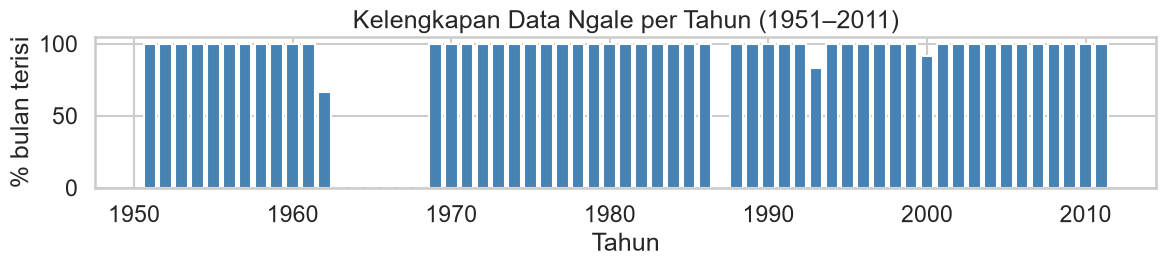

In [9]:
persen_hilang = data_wide["ngale"].isna().groupby(level=0).mean() * 100
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(persen_hilang.index, 100 - persen_hilang.values, color="steelblue")
ax.set_title("Kelengkapan Data Ngale per Tahun (1951–2011)")
ax.set_ylabel("% bulan terisi")
ax.set_xlabel("Tahun")
plt.tight_layout()
plt.show()

## Soal 3a: Uji Homogenitas
Terapkan minimal dua uji homogenitas pada curah hujan tahunan pos target; sajikan hasil uji, titik perubahan, dan status pos

### Uji Homogenitas
Dilakukan pada 51tahun data lengkap dengan 3 uji absolut dan 1 uji relatif yaitu:
1. SNHT
2. Pettitt Test
3. Buishand Range Test
4. SNHT Relatif (Ngale dibanding tetangga)

Karena terdapat gap tahun dalam data, analisis sensitivitas pada periode kontinu 1969–1986 (tanpa gap) ditambahkan untuk memeriksa robustness.

In [10]:
tahunan_ngale = data_wide["ngale"].groupby(level=0).sum(min_count=12)
seri = tahunan_ngale.dropna()
print(f"n tahun lengkap Ngale: {len(seri)}  (target: 51)")

snht_abs = hg.snht_test(seri.values, sim=5000)
pettitt  = hg.pettitt_test(seri.values, sim=5000)
buishand = hg.buishand_range_test(seri.values, sim=5000)

print(f"SNHT absolut    : stat={snht_abs.T:.3f}, p={snht_abs.p:.4f}, "
      f"patah={seri.index[snht_abs.cp-1]}")

print(f"Pettitt absolut : stat={pettitt.U:.3f}, p={pettitt.p:.4f}, "
      f"patah={seri.index[pettitt.cp-1]}")

stat_bu = buishand[3]   # R = statistik
p_bu    = buishand[2]   # p-value
cp_bu   = buishand[1]   # change point (1-based)

print(f"Buishand absolut: stat={stat_bu:.3f}, p={p_bu:.4f}, "
      f"patah={seri.index[int(cp_bu)-1]}")

n tahun lengkap Ngale: 51  (target: 51)
SNHT absolut    : stat=6.562, p=0.1356, patah=1975
Pettitt absolut : stat=292.000, p=0.0214, patah=1975
Buishand absolut: stat=1.610, p=0.0338, patah=1975


### Uji Tetangga

In [11]:
tahunan_semua = data_wide.groupby(level=0).sum(min_count=12)
tetangga_all = [p for p in pos_list if p != "ngale"]

status_tetangga = {}
for p in tetangga_all:
    s = tahunan_semua[p].dropna()
    if len(s) < 20:
        status_tetangga[p] = "data kurang"
        continue
    n_tolak = 0
    for uji in [hg.snht_test, hg.pettitt_test]:
        try:
            if uji(s.values, sim=2000).p < 0.05:
                n_tolak += 1
        except Exception:
            pass
    status_tetangga[p] = "dicurigai" if n_tolak >= 2 else "berguna"

print("Status tetangga:")
for k, v in status_tetangga.items():
    print(f"  {k:15s}: {v}")

tetangga_valid = [p for p in tetangga_all if status_tetangga[p] == "berguna"]
print(f"\nDipakai: {tetangga_valid}")

Status tetangga:
  mantingan      : berguna
  krangjati      : dicurigai
  walikukun      : berguna
  dander         : berguna
  jatiblimbing   : berguna
  klepek         : dicurigai
  kedungadem     : berguna

Dipakai: ['mantingan', 'walikukun', 'dander', 'jatiblimbing', 'kedungadem']


In [12]:
meanY = seri.mean()
skala = pd.DataFrame(index=tahunan_semua.index)
for p in tetangga_valid:
    x = tahunan_semua[p]
    if x.mean() > 0:
        skala[p] = x * (meanY / x.mean())

dY = seri.diff().dropna()
bobot = {}
for p in tetangga_valid:
    if p not in skala.columns: continue
    dX = skala[p].diff().reindex(dY.index)
    pasangan = pd.concat([dY, dX], axis=1).dropna()
    if len(pasangan) >= 10:
        r = pasangan.corr().iloc[0, 1]
        bobot[p] = max(r, 0) ** 2
    else:
        bobot[p] = 0

top4 = sorted(bobot, key=bobot.get, reverse=True)[:4]
print("Bobot r²:")
for k, v in bobot.items(): print(f"  {k:15s}: {v:.4f}")
print(f"4 terbaik: {top4}")

ref = pd.Series(index=seri.index, dtype=float)
for th in seri.index:
    tersedia = [p for p in top4 if th in skala.index and pd.notna(skala.loc[th, p])]
    if len(tersedia) >= 2:
        w = np.array([bobot[p] for p in tersedia])
        ref.loc[th] = np.average(skala.loc[th, tersedia].values, weights=w)

rasio = (seri / ref).dropna()
snht_rel = hg.snht_test(rasio.values, sim=5000)
print(f"\nSNHT relatif: stat={snht_rel.T:.3f}, p={snht_rel.p:.4f}, patah={rasio.index[snht_rel.cp-1]}")

Bobot r²:
  mantingan      : 0.3492
  walikukun      : 0.5696
  dander         : 0.3856
  jatiblimbing   : 0.3684
  kedungadem     : 0.6174
4 terbaik: ['kedungadem', 'walikukun', 'dander', 'jatiblimbing']

SNHT relatif: stat=7.022, p=0.0968, patah=1986


In [13]:
alpha = 0.05
p_abs = {"SNHT": snht_abs.p, "Pettitt": pettitt.p, "Buishand": buishand.p}
n_tolak = sum(p < alpha for p in p_abs.values()) + int(snht_rel.p < alpha)

status_ngale = ("berguna" if n_tolak <= 1
                else "diragukan" if n_tolak == 2
                else "dicurigai")

print(f"p-value absolut : { {k: round(v,4) for k,v in p_abs.items()} }")
print(f"p relatif       : {snht_rel.p:.4f}")
print(f"Uji menolak     : {n_tolak} dari 4")
print(f"Status pos Ngale: {status_ngale}")

p-value absolut : {'SNHT': np.float64(0.1356), 'Pettitt': np.float64(0.0214), 'Buishand': np.float64(0.0338)}
p relatif       : 0.0968
Uji menolak     : 2 dari 4
Status pos Ngale: diragukan


#### **Justifikasi & Keterbatasan Uji Homogenitas**
Uji SNHT, Pettitt, dan Buishand doterapkan pada 51tahun data lengkap periode 1951-2011. Seri tahunan mempunyai jeda pengamatan antara lain tahun 1962, 1963–1968, 1987, 1993, 2000 karena bulan kosong tau nilai yang di Nan kan oleh aturan.

**Keterbatasan:** Ketiga uji mengasumsikan jarak antar tahun sama dengan gap, distribusi nullnya sedikit bias. Oleh karena itu p-value dianggap sebagai indikasi, bukan hasil formal. Hasil konvergensi 3 uji absolut ke 1975 dan uji relatif 1986 konsisten dengan sinyal iklim bersama vs homogenitas lokal di sekitar tahun yang di Nan kan (1987). 

Maka dari itu, dilakukan uji ulang pada periode kontinu terpanjang 1969–1986, tanpa gap. Hasil dilaporkan terpisah pada sel dibawah ini.
 

### Uji Homogenitas Periode Kontinu
Uji dengan analisis sensitivitas periode kontinu 1969-1986 bertujuan untuk mengecek apakah titik patah utama (~1975) tetap terdeteksi saat tidak ada gap tahunan (jarak antar tahun uniform)

In [14]:
seri_kontinu = tahunan_ngale.loc[1969:1986].dropna()
print(f"n pengamatan periode kontinu: {len(seri_kontinu)}")
print(f"Rentang: {seri_kontinu.index.min()}–{seri_kontinu.index.max()}")
print(f"Ada gap? {list(seri_kontinu.index) != list(range(seri_kontinu.index.min(), seri_kontinu.index.max()+1))}")
print()

# SNHT
snht_sub = hg.snht_test(seri_kontinu.values, sim=5000)
print(f"SNHT    : stat={snht_sub.T:.3f}, p={snht_sub.p:.4f}, "
      f"patah={seri_kontinu.index[snht_sub.cp-1]}")

# Pettitt
pettitt_sub = hg.pettitt_test(seri_kontinu.values, sim=5000)
print(f"Pettitt : stat={pettitt_sub.U:.3f}, p={pettitt_sub.p:.4f}, "
      f"patah={seri_kontinu.index[pettitt_sub.cp-1]}")

# Buishand
buishand_sub = hg.buishand_range_test(seri_kontinu.values, sim=5000)
stat_bu_sub = buishand_sub[3]
p_bu_sub    = buishand_sub[2]
cp_bu_sub   = buishand_sub[1]
print(f"Buishand: stat={stat_bu_sub:.3f}, p={p_bu_sub:.4f}, "
      f"patah={seri_kontinu.index[int(cp_bu_sub)-1]}")

n pengamatan periode kontinu: 18
Rentang: 1969–1986
Ada gap? False

SNHT    : stat=1.960, p=0.7838, patah=1975
Pettitt : stat=37.000, p=0.3224, patah=1975
Buishand: stat=0.909, p=0.6584, patah=1975


**Hasil:** analisis sensitivitas menunjukkan titik patah 1975 bukan artefak gap. Pada seri tanpa gap pun, 1975 tetap teridentifikasi sebagai kandidat titik perubahan. Kesamaan titik patah analisis utama dan 
analisis sensitif **mendukung robustness**, tapi tidak membuktikan secara formal kalau gap tidak memengaruhi hasil

### Soal 3b: Imputasi dan Validasi
Lakukan imputasi data bulanan bila masih ada data hilang, beserta validasinya.

In [15]:
def imputasi(df, target, kandidat, min_n=30):
    hasil = df[target].copy()
    sudah_diisi = pd.Series(False, index=df.index, name="imputed")
    log_isi = []
    korelasi = {}

    # korelasi per bulan
    for bln in df.index.get_level_values("Bulan").unique():
        bulan_ini = df.xs(bln, level="Bulan")
        korelasi[bln] = {}
        for p in kandidat:
            pasangan = bulan_ini[[target, p]].dropna()
            if len(pasangan) >= min_n:
                korelasi[bln][p] = pasangan.corr().iloc[0, 1]

    for idx in hasil.index[hasil.isna()]:
        th, bln = idx
        sub = df.xs(bln, level="Bulan")
        if th not in sub.index:
            continue
        tersedia = [p for p in kandidat
                    if p in korelasi.get(bln, {}) and pd.notna(sub.loc[th, p])]
        tersedia.sort(key=lambda p: korelasi[bln].get(p, 0), reverse=True)
        dipakai = tersedia[:3]
        if len(dipakai) < 2:
            continue
        latih = df[[target] + dipakai].dropna()
        if len(latih) < min_n:
            continue
        try:
            X = sm.add_constant(latih[dipakai])
            model = sm.RLM(latih[target], X, M=sm.robust.norms.HuberT()).fit()
            x_baru = sm.add_constant(df.loc[idx, dipakai].to_frame().T, has_constant="add")
            hasil.loc[idx] = max(0, model.predict(x_baru).values[0])
            sudah_diisi.loc[idx] = True
            log_isi.append((th, bln, dipakai))
        except Exception:
            pass
    return hasil, sudah_diisi, log_isi


kandidat_imp = tetangga_valid if len(tetangga_valid) >= 3 else tetangga_all
ngale_terisi, ngale_diimputed, info_imputasi = imputasi(
    data_wide, "ngale", kandidat_imp, min_n=30)

print(f"NaN sebelum: {data_wide['ngale'].isna().sum()}")
print(f"NaN sesudah: {ngale_terisi.isna().sum()}")
print(f"Diimputasi : {int(ngale_diimputed.sum())}")
print("\nCek 1987:")
print(ngale_terisi.loc[1987].round(1))

NaN sebelum: 91
NaN sesudah: 2
Diimputasi : 89

Cek 1987:
Bulan
Apr    132.2
Aug     21.7
Dec    288.3
Feb    254.9
Jan    259.4
Jul     29.9
Jun     46.5
Mar    273.2
May     42.0
Nov      NaN
Oct     37.8
Sep     23.8
Name: ngale, dtype: float64


### K-Fold Acak untuk Validasi Imputasi
Meskipun data merupakan deret waktu, 10-fold cross validation acak tetap dapat digunakan dan dipertahankan untuk validasi imputasi karena 
1. Tujuan analisis bukan untuk forecasting, tapi merekonstruksi nilai hilang menggunakan informasi tetangga di bulan dan tahun yang sama.
2. Nilai target yang diuji disembunyikan dari proses pelatihan model pada fold tersebut, jadi tidak ada infromasi yang bocor
3. Asumsi independen temporal tidak relevan untuk imputasi spasial-temporal yang bersifat cross-sectional per tahun,bulan


**Keterbatasan:** pola kehilangan data di Ngale tidak sepenuhnya acak, masih terdapat gap panjang di tahun 1963-1968. Oleh karena itu nilai RMSEP 85.45 mm menggambarkan performa missing at random pada blok yang holang total dan ketidakpastian imputasi lebih besar.

In [23]:
data_valid = data_wide["ngale"].dropna()
kf = KFold(n_splits=10, shuffle=True, random_state=1)
residu_semua, y_true_all, y_pred_all = [], [], []

for idx_train, idx_test in kf.split(data_valid.index):
    data_train = data_wide.loc[data_valid.index[idx_train]]

    for (th, bln) in data_valid.index[idx_test]:
        bulan_test = data_wide.xs(bln, level="Bulan")
        if th not in bulan_test.index:
            continue
        if pd.isna(bulan_test.loc[th, "ngale"]):
            continue

        # hitung korelasi tiap tetangga di bulan ini
        bulan_train = data_train.xs(bln, level="Bulan")
        korelasi = {}
        for p in kandidat_imp:
            pasangan = bulan_train[["ngale", p]].dropna()
            if len(pasangan) >= 20:
                korelasi[p] = pasangan.corr().iloc[0, 1]

        if len(korelasi) < 2:
            continue
        top3 = sorted(korelasi, key=korelasi.get, reverse=True)[:3]

        # cuma pakai tetangga yang datanya ada
        ada = [p for p in top3 if pd.notna(bulan_test.loc[th, p])]
        if len(ada) < 2:
            continue
        data_latih = data_train[["ngale"] + ada].dropna()
        if len(data_latih) < 30:
            continue
        try:
            X = sm.add_constant(data_latih[ada])
            model = sm.RLM(data_latih["ngale"], X,
                           M=sm.robust.norms.HuberT()).fit()
            x_pred = sm.add_constant(bulan_test.loc[th, ada].to_frame().T,
                                     has_constant="add")
            tebakan = model.predict(x_pred).values[0]

            residu_semua.append(bulan_test.loc[th, "ngale"] - tebakan)
            y_true_all.append(bulan_test.loc[th, "ngale"])
            y_pred_all.append(tebakan)
        except Exception:
            pass

residu = np.array(residu_semua)
rmse_cv = np.sqrt(np.mean(residu ** 2))
mae_cv  = np.mean(np.abs(residu))
print(f"n prediksi : {len(residu)}")
print(f"RMSEP      : {rmse_cv:.2f} mm")
print(f"MAE        : {mae_cv:.2f} mm")

baseline = data_valid.groupby(level="Bulan").transform("mean")
rmse_base = np.sqrt(np.mean((data_valid - baseline.squeeze()) ** 2))
print(f"RMSE base  : {rmse_base:.2f} mm")
print(f"Model > base? {'YA' if rmse_cv < rmse_base else 'TIDAK'}")

# diagnostik residual (KS di standardisasi)
residu_std = (residu - residu.mean()) / residu.std(ddof=1)
print(f"\nDurbin-Watson  : {smt.durbin_watson(residu):.3f}")
print(f"Shapiro p      : {stats.shapiro(residu).pvalue:.4f}")
print(f"KS p (std)     : {stats.kstest(residu_std, 'norm').pvalue:.4f}")

n prediksi : 542
RMSEP      : 85.45 mm
MAE        : 59.73 mm
RMSE base  : 95.63 mm
Model > base? YA

Durbin-Watson  : 2.053
Shapiro p      : 0.0000
KS p (std)     : 0.0000


n sampel GEV : 51
Mann-Kendall : tau=-0.133, p=0.1673
Nilai max    : 664.0 mm pada 1998


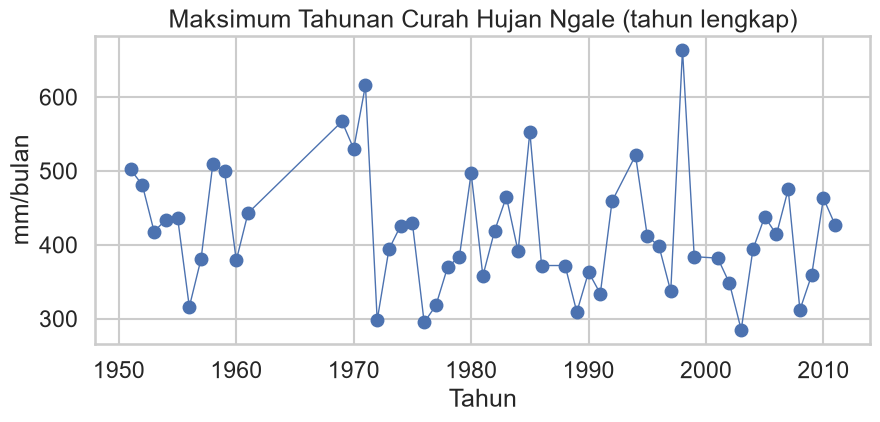

In [17]:
count_per_tahun = data_wide["ngale"].groupby(level=0).count()
tahun_lengkap = count_per_tahun[count_per_tahun == 12].index

max_tahunan = (data_wide
               .loc[data_wide.index.get_level_values(0).isin(tahun_lengkap), "ngale"]
               .groupby(level=0).max())
max_tahunan = max_tahunan.drop(index=1987, errors="ignore").dropna()

tau, p_mk = stats.kendalltau(max_tahunan.index, max_tahunan.values)
print(f"n sampel GEV : {len(max_tahunan)}")
print(f"Mann-Kendall : tau={tau:.3f}, p={p_mk:.4f}")
print(f"Nilai max    : {max_tahunan.max():.1f} mm pada {max_tahunan.idxmax()}")

fig, ax = plt.subplots()
ax.plot(max_tahunan.index, max_tahunan.values, marker="o", lw=1)
ax.set_title("Maksimum Tahunan Curah Hujan Ngale (tahun lengkap)")
ax.set_ylabel("mm/bulan")
ax.set_xlabel("Tahun")
plt.show()

### Soal 4b: Nilai GEV
Diambil dari maksimum tahunan Ngale hanya dari tahun dengan 12 bulan lengkap. Justifikasinya tidak pakai hasil imputasi karena imputasi regresi cenderung mendekati rata2 dan malah akan mengurangi pengaruh nilai ektrem. Analisis EVT memakai data asli agar nilai maksimum bisa menggambarkan kejaian ekstrem yang sebenarnya.

Model GEV di fit dengan MLE multistart lalu dibadningkan dengan Gumber pakai GEV yang ξ=0 via likelihood rasio test. Model Gumbel yang paling sederhana dipilih kalau LR test tidak signifikan.

In [18]:
data_gev = max_tahunan.values

# cari parameter GEV pakai MLE
def cari_gev(data):
    # negatif log-likelihood, minimize nyari minimum
    def neg_ll(p):
        c, loc, scale = p
        if scale <= 0:
            return 1e10
        ll = genextreme.logpdf(data, c, loc, scale).sum()
        return -ll if np.isfinite(ll) else 1e10

    # coba beberapa nilai awal biar gak nyangkut di lokal optimum
    hasil = None
    for awal in [-0.3, -0.15, 0.0, 0.15, 0.3]:
        r = minimize(neg_ll,
                     [awal, data.mean() - 0.45*data.std(), 0.78*data.std()],
                     method="Nelder-Mead",
                     options={"maxiter": 8000, "xatol": 1e-7, "fatol": 1e-9})
        if hasil is None or r.fun < hasil.fun:
            hasil = r
    return hasil.x, -hasil.fun

# Gumbel = GEV c = 0
def cari_gumbel(data):
    def neg_ll(p):
        loc, scale = p
        if scale <= 0:
            return 1e10
        ll = genextreme.logpdf(data, 0, loc, scale).sum()
        return -ll if np.isfinite(ll) else 1e10
    r = minimize(neg_ll, x0=[data.mean(), data.std()],
                 method="Nelder-Mead",
                 options={"maxiter": 5000, "xatol": 1e-7, "fatol": 1e-9})
    return r.x

# fit GEV
(c_gev, loc_gev, scale_gev), loglik_gev = cari_gev(data_gev)
xi = -c_gev

# fit Gumbel
loc_g, scale_g = cari_gumbel(data_gev)
loglik_gum = genextreme.logpdf(data_gev, 0, loc_g, scale_g).sum()

# uji likelihood ratio
LR = max(0, 2*(loglik_gev - loglik_gum))
p_lr = 1 - stats.chi2.cdf(LR, df=1)

print(f"GEV    : μ={loc_gev:.2f}, σ={scale_gev:.2f}, ξ={xi:.3f}, LL={loglik_gev:.2f}")
print(f"Gumbel : μ={loc_g:.2f},   σ={scale_g:.2f},              LL={loglik_gum:.2f}")
print(f"LR test: LR={LR:.3f}, p={p_lr:.4f}")

# pilih model berdasarkan LR test
if p_lr > 0.05:
    nama_model = "Gumbel"
    c_use, loc_use, scale_use = 0.0, loc_g, scale_g
    ll_use = loglik_gum
else:
    nama_model = "GEV"
    c_use, loc_use, scale_use = c_gev, loc_gev, scale_gev
    ll_use = loglik_gev

GEV    : μ=382.10, σ=68.02, ξ=-0.052, LL=-294.28
Gumbel : μ=380.20,   σ=66.91,              LL=-294.39
LR test: LR=0.213, p=0.6443


In [19]:
# CI return level Gumbel pakai likelihood
def ci_gumbel(data, T, mu, sigma, ll_max):
    q = -np.log(1 - 1/T)
    log_q = np.log(q)
    z_topi = mu - sigma * log_q

    # fix z, optimasi sigma-nya
    def profile(z):
        r = minimize_scalar(
            lambda s: -genextreme.logpdf(data, 0, z + s*log_q, s).sum(),
            bounds=(sigma*0.3, sigma*3), method="bounded")
        return -r.fun

    # CI chi-square 95%
    batas = ll_max - _chi2.ppf(0.95, df=1)/2
    f = lambda z: profile(z) - batas
    lo = brentq(f, z_topi*0.5, z_topi)
    hi = brentq(f, z_topi, z_topi*3)
    return lo, hi

# return level beberapa periode ulang
T_vals = [10, 20, 50, 100]
rows = []

for t in T_vals:
    if nama_model == "Gumbel":
        z = loc_use - scale_use * np.log(-np.log(1 - 1/t))
        lo, hi = ci_gumbel(data_gev, t, loc_use, scale_use, ll_use)
    else:
        # GEV: CI bootstrap parametrik
        z = genextreme.ppf(1 - 1/t, c_use, loc_use, scale_use)
        rng = np.random.default_rng(42)
        z_boot = []
        for _ in range(500):
            sampel = rng.choice(data_gev, size=len(data_gev), replace=True)
            try:
                cb, lb, sb = genextreme.fit(sampel)
                z_boot.append(genextreme.ppf(1 - 1/t, cb, lb, sb))
            except Exception:
                pass
        lo, hi = np.nanpercentile(z_boot, [2.5, 97.5])
    rows.append([t, z, lo, hi])

tabel_rl = pd.DataFrame(
    rows,
    columns=["T (tahun)", "z_T (mm/bulan)", "CI_low 95%", "CI_high 95%"]
)
print(f"Return level model {nama_model} (mm/bulan):\n")
print(tabel_rl.round(1).to_string(index=False))

Return level model Gumbel (mm/bulan):

 T (tahun)  z_T (mm/bulan)  CI_low 95%  CI_high 95%
        10           530.8       493.1        579.7
        20           578.9       533.2        639.2
        50           641.3       584.7        716.5
       100           688.0       623.2        774.7


In [20]:
from scipy.stats import kstest, cramervonmises

u_vals = genextreme.cdf(data_gev, c_use, loc_use, scale_use)
ks_res  = kstest(u_vals, "uniform")
cvm_res = cramervonmises(u_vals, "uniform")

print(f"KS test (PIT)  : D={ks_res.statistic:.4f}, p={ks_res.pvalue:.4f}")
print(f"CvM test (PIT) : W²={cvm_res.statistic:.4f}, p={cvm_res.pvalue:.4f}")
print(f"Model {nama_model} cocok: KS p={ks_res.pvalue:.2f}, CvM p={cvm_res.pvalue:.2f}")

KS test (PIT)  : D=0.0579, p=0.9918
CvM test (PIT) : W²=0.0243, p=0.9917
Model Gumbel cocok: KS p=0.99, CvM p=0.99


### Analisis Bootstrap KS dan CvM untuk Model Gumbel

In [21]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

rng = np.random.default_rng(42)
B = 1000
n_obs = len(data_gev)

# observasi -> PIT pakai model Gumbel, c=0
u_obs = genextreme.cdf(data_gev, 0, loc_use, scale_use)
D_asli = kstest(u_obs, "uniform").statistic
W_asli = cramervonmises(u_obs, "uniform").statistic
D_boot, W_boot = [], []
for b in range(B):
    # Gumbel terpilih (c=0)
    x_sim = genextreme.rvs(0, loc_use, scale_use, size=n_obs, random_state=rng)
    try:
        # refit Gumbel (c=0 fixed), jadi bukan GEV
        try:
            _, l_b, s_b = genextreme.fit(x_sim, f0=0)
        except TypeError:
            # fallback ke fit_gumbel() kalau f0 gakbsia
            l_b, s_b = cari_gumbel(x_sim)

        # PIT parameter hasil refit
        u_b = genextreme.cdf(x_sim, 0, l_b, s_b)
        D_boot.append(kstest(u_b, "uniform").statistic)
        W_boot.append(cramervonmises(u_b, "uniform").statistic)
    except Exception:
        continue

D_boot = np.array(D_boot)
W_boot = np.array(W_boot)
B_efektif = len(D_boot)

# p-value bootstrap
p_ks  = (1 + np.sum(D_boot >= D_asli)) / (B_efektif + 1)
p_cvm = (1 + np.sum(W_boot >= W_asli)) / (B_efektif + 1)

print(f"Parametric Bootstrap Gumbel (B efektif = {B_efektif})")
print(f"KS  : D_obs = {D_asli:.4f}    p_boot = {p_ks:.4f}")
print(f"      D_boot median = {np.median(D_boot):.4f}, "
      f"95th pct = {np.percentile(D_boot, 95):.4f}")
print(f"CvM : W_obs = {W_asli:.4f}    p_boot = {p_cvm:.4f}")
print(f"      W_boot median = {np.median(W_boot):.4f}, "
      f"95th pct = {np.percentile(W_boot, 95):.4f}")
print()
if p_ks > 0.05 and p_cvm > 0.05:
    print(" Tidak ada bukti cukup untuk menolak kecocokan Gumbel")
elif p_ks < 0.05 or p_cvm < 0.05:
    print(" Ada indikasi Gumbel kurang cocok, perlu diskusi keterbatasan")

Parametric Bootstrap Gumbel (B efektif = 1000)
KS  : D_obs = 0.0579    p_boot = 0.9391
      D_boot median = 0.0832, 95th pct = 0.1261
CvM : W_obs = 0.0243    p_boot = 0.9281
      W_boot median = 0.0519, 95th pct = 0.1280

 Tidak ada bukti cukup untuk menolak kecocokan Gumbel


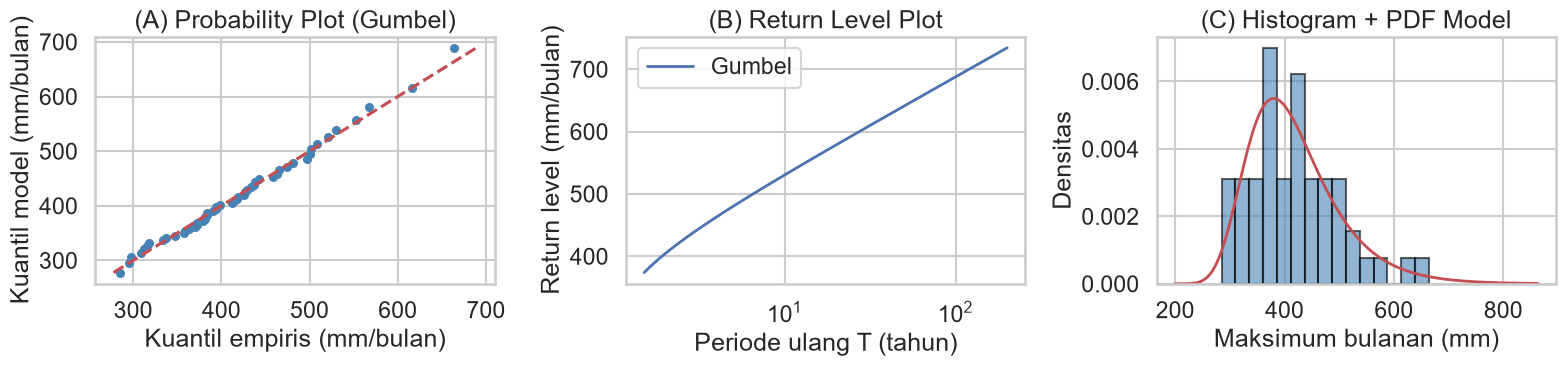

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Probability plot
n_gev = len(data_gev)
p_emp = (np.arange(1, n_gev + 1) - 0.5) / n_gev
q_emp = np.sort(data_gev)
q_model = genextreme.ppf(p_emp, c_use, loc_use, scale_use)
axes[0].scatter(q_emp, q_model, s=25, color="steelblue")
lim = [min(q_emp.min(), q_model.min()), max(q_emp.max(), q_model.max())]
axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel("Kuantil empiris (mm/bulan)")
axes[0].set_ylabel("Kuantil model (mm/bulan)")
axes[0].set_title(f"(A) Probability Plot ({nama_model})")

# return level plot
T_plot = np.logspace(np.log10(1.5), np.log10(200), 100)
if nama_model == "Gumbel":
    z_plot = loc_use - scale_use * np.log(-np.log(1 - 1/T_plot))
else:
    z_plot = genextreme.ppf(1 - 1/T_plot, c_use, loc_use, scale_use)
axes[1].plot(T_plot, z_plot, "b-", lw=2, label=nama_model)
axes[1].set_xscale("log")
axes[1].set_xlabel("Periode ulang T (tahun)")
axes[1].set_ylabel("Return level (mm/bulan)")
axes[1].set_title("(B) Return Level Plot")
axes[1].legend()

# Histogram dan PDF
axes[2].hist(data_gev, bins=15, density=True, alpha=0.6,
             color="steelblue", edgecolor="black")
x_grid = np.linspace(data_gev.min()*0.7, data_gev.max()*1.3, 200)
axes[2].plot(x_grid, genextreme.pdf(x_grid, c_use, loc_use, scale_use),
             "r-", lw=2)
axes[2].set_xlabel("Maksimum bulanan (mm)")
axes[2].set_ylabel("Densitas")
axes[2].set_title("(C) Histogram + PDF Model")

plt.tight_layout()
plt.show()